In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [19]:
spy = pd.read_excel("SPY Monthly.xlsx")

In [20]:
spy.head()
spy.columns
spy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 5 columns):
 #   Column                                  Non-Null Count  Dtype         
---  ------                                  --------------  -----         
 0   Date                                    122 non-null    datetime64[ns]
 1   Fund Identifier                         122 non-null    int64         
 2   Total Net Assets as of Month End        122 non-null    float64       
 3   Total Return per Share as of Month End  122 non-null    float64       
 4   Monthly Net Asset Value Per Share       122 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(1)
memory usage: 4.9 KB


In [21]:
spy = spy.rename(columns={
    "Date": "date",
    "Total Net Assets as of Month End": "tna",
    "Total Return per Share as of Month End": "ret",
    "Monthly Net Asset Value Per Share": "nav"
})

In [22]:
spy["ret"].describe()

count    122.000000
mean       0.012139
std        0.043258
min       -0.122569
25%       -0.008587
50%        0.019120
75%        0.036852
max        0.127956
Name: ret, dtype: float64

In [23]:
spy.columns

Index(['date', 'Fund Identifier', 'tna', 'ret', 'nav'], dtype='object')

In [24]:
spy.columns = [
    "date",
    "fund_id",
    "tna",
    "ret",
    "nav"
]

In [25]:
spy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   date     122 non-null    datetime64[ns]
 1   fund_id  122 non-null    int64         
 2   tna      122 non-null    float64       
 3   ret      122 non-null    float64       
 4   nav      122 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(1)
memory usage: 4.9 KB


In [26]:
spy["tna_lag"] = spy["tna"].shift(1)

spy["net_flow"] = spy["tna"] - (spy["tna_lag"] * (1 + spy["ret"]))

spy["flow_spy"] = spy["net_flow"] / spy["tna_lag"]

spy = spy.dropna()

In [27]:
spy[["tna", "ret", "net_flow", "flow_spy"]].head()
spy["flow_spy"].describe()

count    121.000000
mean       0.000791
std        0.026779
min       -0.066555
25%       -0.016843
50%        0.001231
75%        0.014323
max        0.093540
Name: flow_spy, dtype: float64

In [28]:
spy_flow = spy[["date", "flow_spy"]]

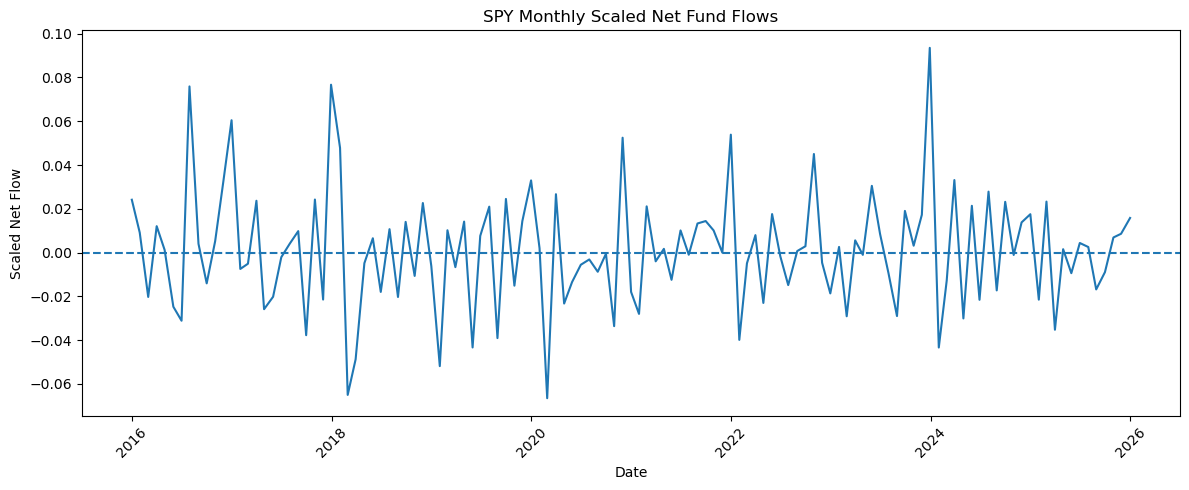

In [29]:
plt.figure(figsize=(12,5))

plt.plot(spy["date"], spy["flow_spy"])
plt.axhline(0, linestyle="--")

plt.title("SPY Monthly Scaled Net Fund Flows")
plt.xlabel("Date")
plt.ylabel("Scaled Net Flow")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [30]:
spy[["date", "flow_spy"]].head()

,date,flow_spy
1,2015-12-31,0.024138
2,2016-01-29,0.009106
3,2016-02-29,-0.020284
4,2016-03-31,0.012057
5,2016-04-29,0.001231


In [31]:
spy = spy.copy()

spy["date"] = pd.to_datetime(spy["date"])
spy["date"] = spy["date"] + pd.offsets.MonthEnd(0)

In [32]:
spy[["date", "flow_spy"]].head()

,date,flow_spy
1,2015-12-31,0.024138
2,2016-01-31,0.009106
3,2016-02-29,-0.020284
4,2016-03-31,0.012057
5,2016-04-30,0.001231


In [33]:
spy_final = spy[["date", "flow_spy"]].copy()
spy_final = spy_final.sort_values("date")

spy_final.to_csv("spy_clean.csv", index=False)

In [34]:
spy_final.head()
spy_final.tail()

,date,flow_spy
117,2025-08-31,-0.016843
118,2025-09-30,-0.008956
119,2025-10-31,0.006892
120,2025-11-30,0.008579
121,2025-12-31,0.015811
